# HW2｜FloodProbability 多元線性回歸
以 CRISP-DM 完成資料稽核、訓練內特徵選擇、模型比較與獨立校準的 95% 預測區間。

原始資料來自 Kaggle S4E5 的公開鏡像，屬合成 benchmark；不是經驗證的真實洪災預警模型。

學號：7114056093（由 config.json 設定）。

## 執行與資料邊界
固定 seed=42。先保留 20% 測試集，再將剩餘資料的 20% 作為校準集。僅從真正訓練部分抽取 80,000 筆執行五折 CV；選定模型後在完整訓練部分擬合。下列儲存格會實際重新執行完整實驗，約數分鐘，並更新 outputs/。

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
for variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[variable] = '1'
print('專案根目錄：', ROOT)

專案根目錄： /user_data/IoT/HW2


In [2]:
from src.run_experiment import run
results = run()
display(results[['model', 'features', 'cv_rmse', 'mae', 'rmse', 'r2']])

資料稽核完成： (1117957, 22) CV 子樣本： 80000


LR_All CV RMSE=0.020181


LR_KBest_5 CV RMSE=0.046224


LR_RFE_5 CV RMSE=0.046287


LR_KBest_10 CV RMSE=0.040316


...

測試診斷： Ridge_0.1 0.020079982748870944


測試診斷： Lasso_1e-05 0.02008010238216868


測試診斷： HGB_Summary 0.01855927238563922


完整實驗完成，耗時秒數： 104.7


,model,features,cv_rmse,mae,rmse,r2
0,LR_All,20,0.020181,0.015795,0.020080,0.844878
1,LR_KBest_15,15,0.032437,0.026089,0.032414,0.595791
2,LR_RFE_15,15,0.032349,0.026111,0.032425,0.595506
3,LR_LassoSelect,20,0.020181,0.015795,0.020080,0.844878
4,Ridge_0.1,20,0.020181,0.015795,0.020080,0.844878
5,Lasso_1e-05,20,0.020181,0.015798,0.020080,0.844876
6,HGB_Summary,20,0.018732,0.014497,0.018559,0.867484


## 資料理解與特徵選擇
KBest 使用 f_regression；RFE 以 LinearRegression 遞迴刪除；LassoCV 在原始相同評分尺度進行三折內層選擇，再接 imputer、scaler 與 OLS。其他模型在每個 CV fold 內完整擬合 Pipeline。校準與測試資料皆不參與選擇。

In [3]:
import pandas as pd
display(pd.read_csv('outputs/tables/cv_results.csv'))
display(pd.read_csv('outputs/tables/lasso_selection.csv'))
print(Path('outputs/tables/selection_lock.json').read_text())

,model,cv_rmse,cv_sd,cv_n,mean_selected_features,seconds
0,LR_All,0.020181,0.000061,80000,20.0,0.809972
1,LR_KBest_5,0.046224,0.000222,80000,5.0,0.751295
2,LR_RFE_5,0.046287,0.000274,80000,5.0,1.080791
3,LR_KBest_10,0.040316,0.000145,80000,10.0,0.767986
4,LR_RFE_10,0.040378,0.000194,80000,10.0,1.061188
5,LR_KBest_15,0.032437,0.000126,80000,15.0,0.815408
6,LR_RFE_15,0.032349,0.000073,80000,15.0,1.042300
7,LR_LassoSelect,0.020181,0.000061,80000,20.0,1.276957
8,Ridge_0.1,0.020181,0.000061,80000,20.0,0.726488
9,Ridge_10,0.020181,0.000061,80000,20.0,0.727853


,feature,lasso_cv_coefficient,retained
0,MonsoonIntensity,0.005610,True
1,TopographyDrainage,0.005635,True
2,RiverManagement,0.005660,True
3,Deforestation,0.005671,True
4,Urbanization,0.005655,True
5,ClimateChange,0.005650,True
6,DamsQuality,0.005646,True
7,Siltation,0.005632,True
8,AgriculturalPractices,0.005627,True
9,Encroachments,0.005639,True


{
  "primary": "LR_All",
  "overall_cv_winner": "HGB_Summary",
  "diagnostic_models": [
    "LR_All",
    "LR_KBest_15",
    "LR_RFE_15",
    "LR_LassoSelect",
    "Ridge_0.1",
    "Lasso_1e-05",
    "HGB_Summary"
  ],
  "selection_rule": "僅依訓練子樣本五折 CV RMSE；主要模型限制為 LinearRegression。",
  "locked_at_utc": "2026-10-19T09:59:30.177533+00:00",
  "test_accessed": false,
  "parameters": {
    "LR_All": "Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),\n                ('scaler', StandardScaler()), ('selector', 'passthrough'),\n                ('model', LinearRegression())])",
    "LR_KBest_15": "Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),\n                ('scaler', StandardScaler()),\n                ('selector',\n                 SelectKBest(k=15,\n                             score_func=<function f_regression at 0x7f041bcf5670>)),\n                ('model', LinearRegression())])",
    "LR_RFE_15": "Pipeline(steps=[('imputer', SimpleImputer(strategy='median'

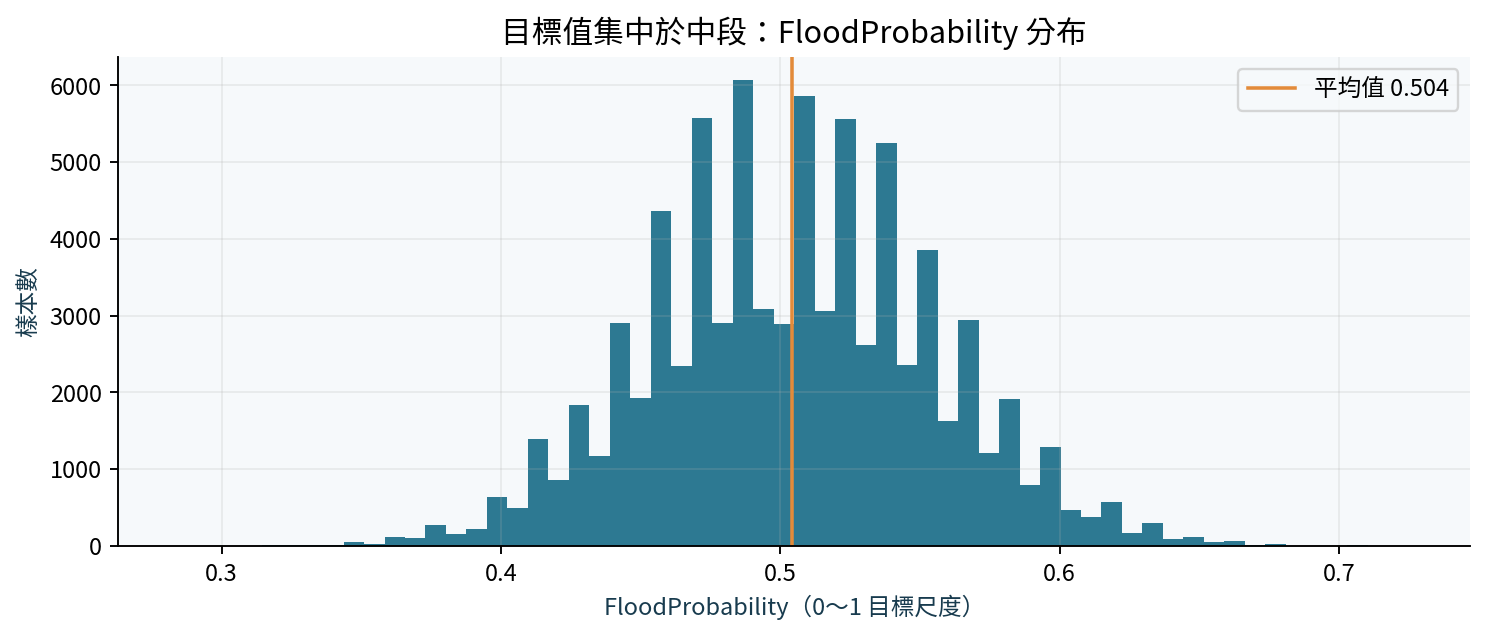

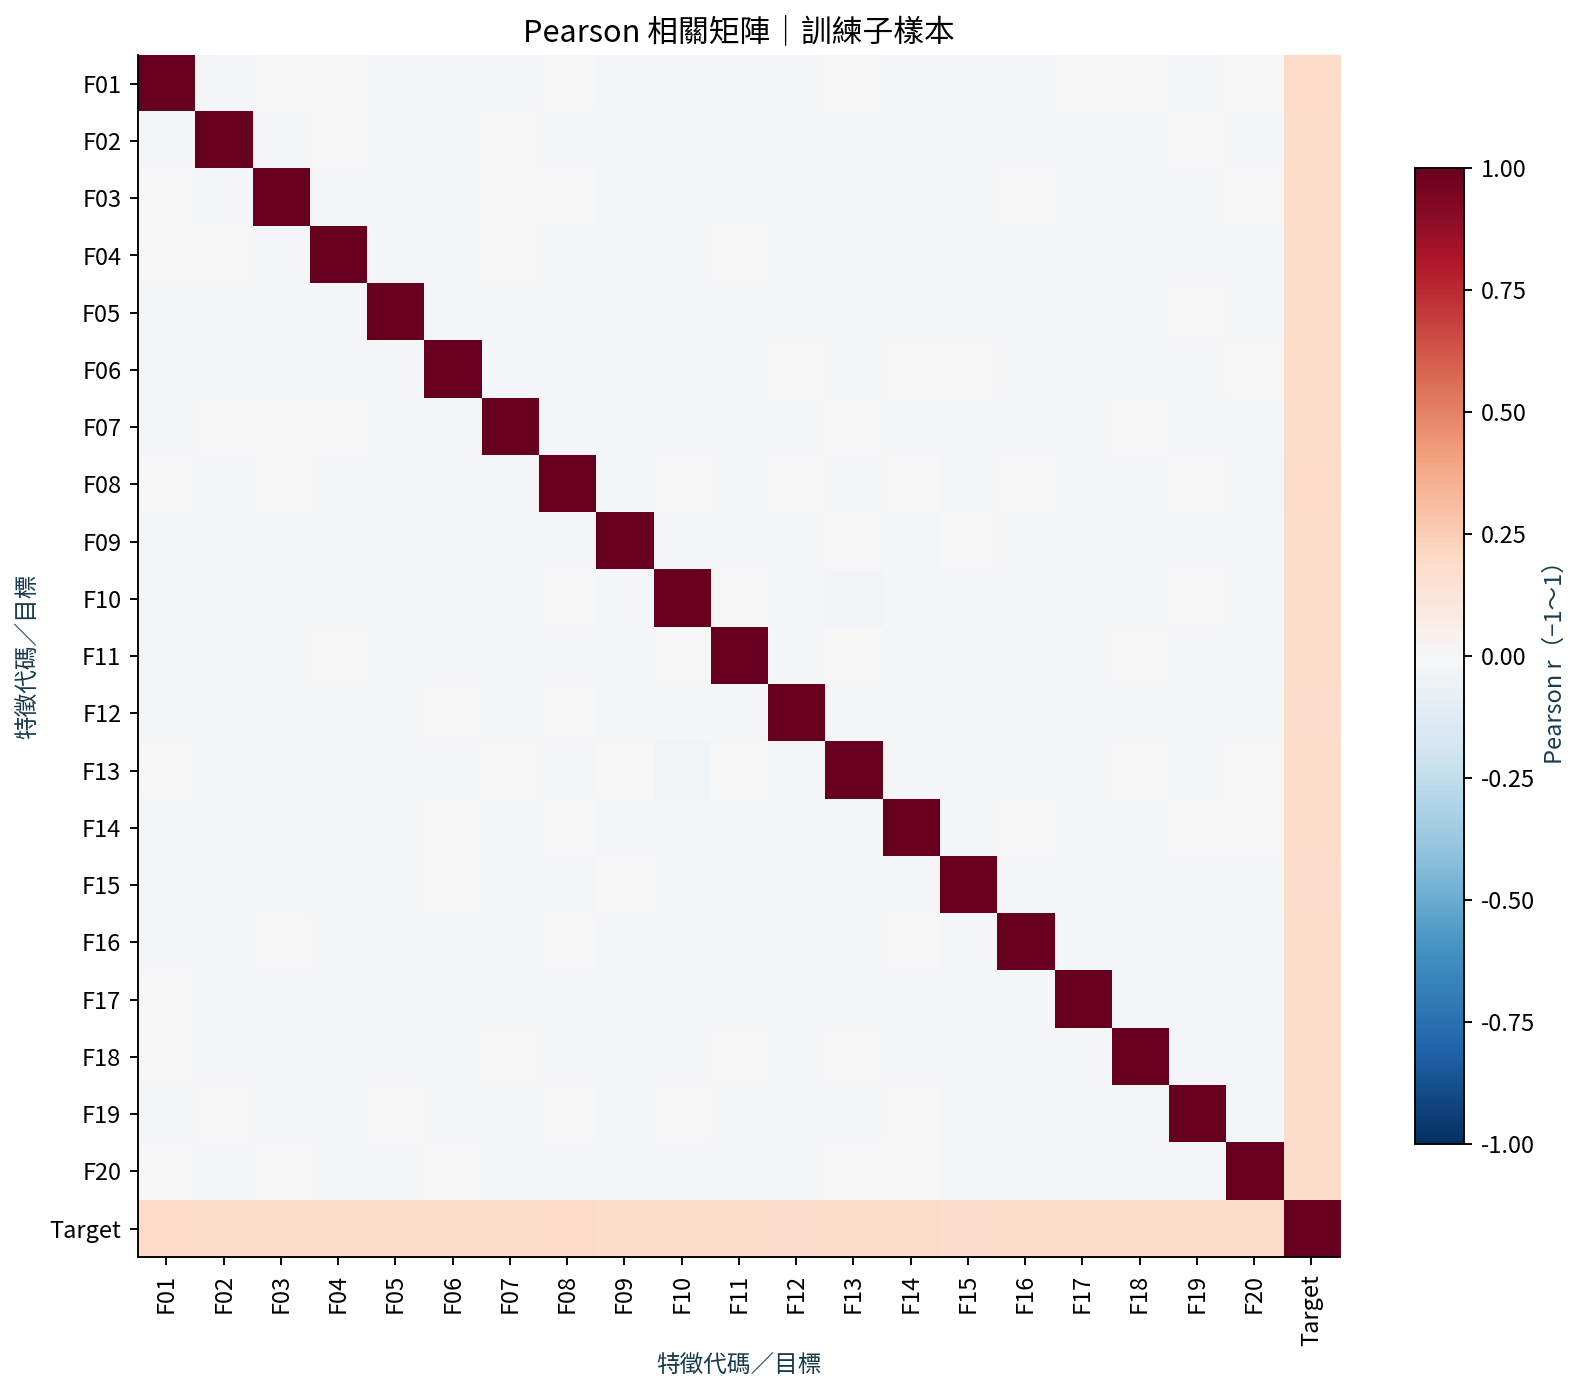

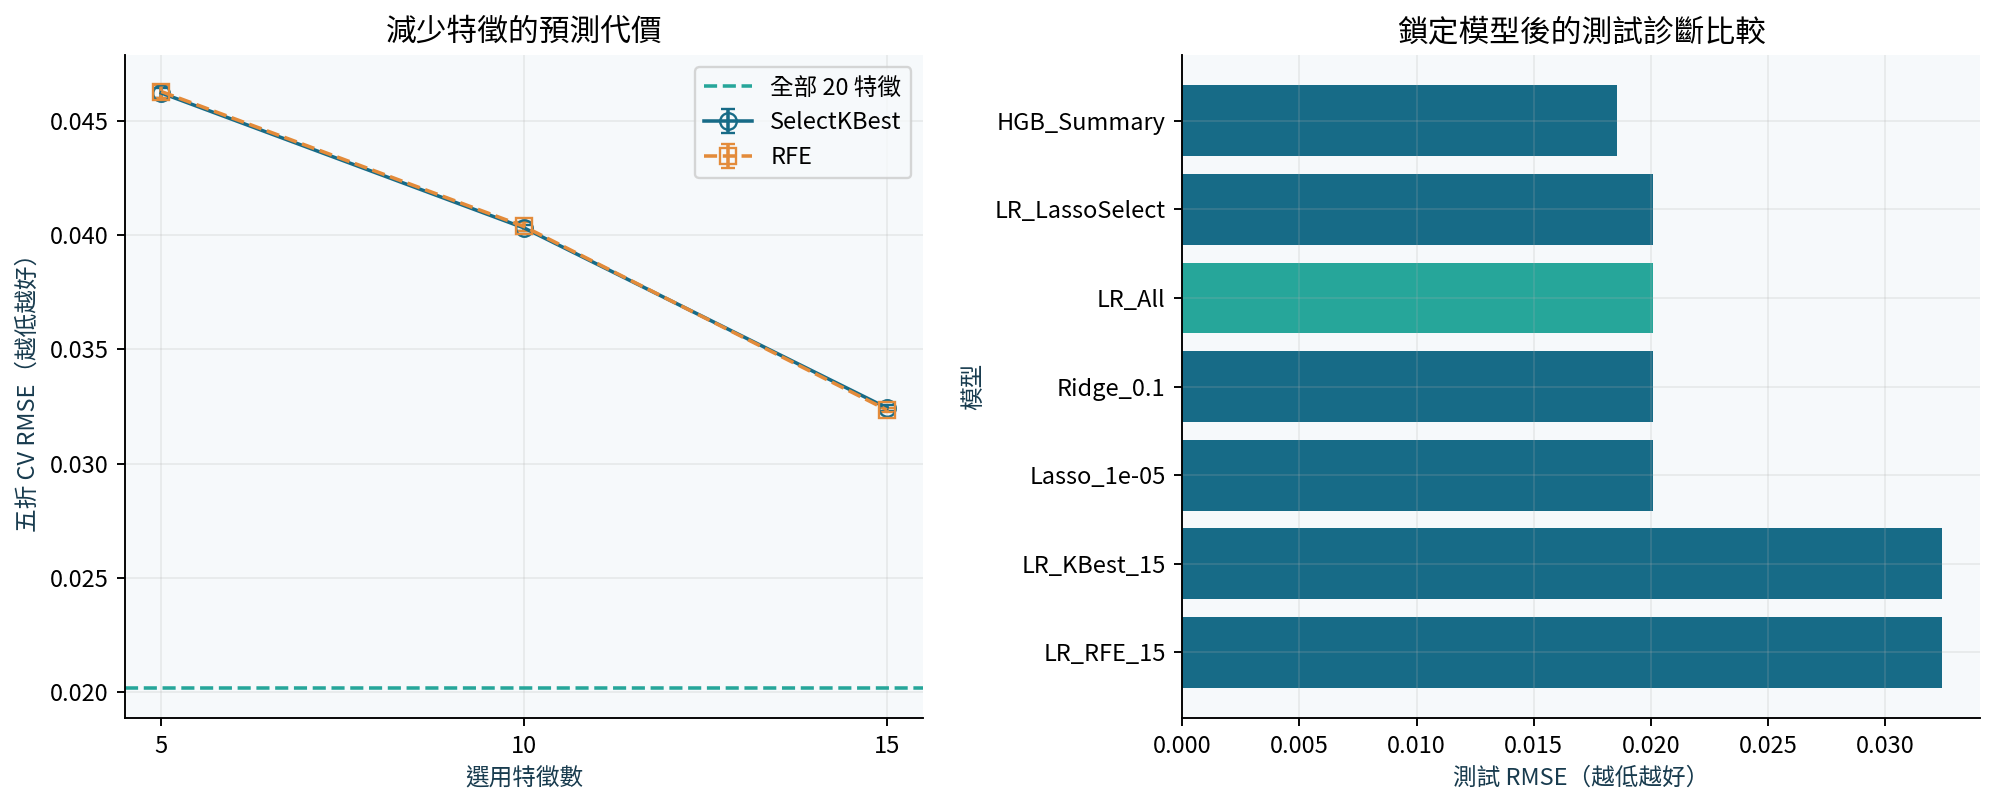

In [4]:
from IPython.display import display, Image
for name in ['01_target_distribution', '03_correlation_heatmap', '09_model_comparison']:
    display(Image(filename=f'outputs/figures/{name}.png', width=850))

## 評估與不確定性
下表多個測試分數僅為模型鎖定後的診斷；不能依測試分數改選主模型。Conformal 區間的校準誤差取第 ceil((n+1)×0.95) 個排序值。其保證為交換性條件下的邊際涵蓋，不代表每個風險區段均達 95%。

{
  "method": "Split conformal, absolute residual, finite-sample quantile",
  "nominal_coverage": 0.95,
  "q": 0.04005815443018501,
  "quantile_rank": 169931,
  "calibration_n": 178873,
  "test_n": 223592,
  "coverage": 0.9496672510644388,
  "average_width": 0.08011630886037002,
  "prediction_out_of_bounds": 0,
  "lower_out_of_bounds": 0,
  "upper_out_of_bounds": 0
}
{
  "diagnostic_n": 80000,
  "breusch_pagan_lm": 3464.676489156044,
  "breusch_pagan_p": 0.0,
  "breusch_pagan_f_p": 0.0,
  "durbin_watson": 2.002697021303836,
  "jarque_bera": 10280.326532150557,
  "jarque_bera_p": 0.0,
  "residual_skew": 0.704911586271026,
  "residual_kurtosis": 4.047137327101193,
  "max_vif": 1.004336348091196,
  "max_absolute_feature_correlation": 0.02432411524602922,
  "rank": 21,
  "condition_number": 265.440609893288
}


,prediction_bin,n,mae,mse,rmse,r2,adjusted_r2,coverage,average_width,prediction_out_of_bounds,lower_out_of_bounds,upper_out_of_bounds
0,"(0.302, 0.455]",22360,0.015438,0.000474,0.021776,0.389793,NaN,0.882513,0.080116,0,0,0
1,"(0.455, 0.466]",22359,0.023875,0.000793,0.028161,0.020249,NaN,0.845879,0.080116,0,0,0
2,"(0.466, 0.478]",22359,0.023119,0.000676,0.025991,-0.006374,NaN,0.952234,0.080116,0,0,0
3,"(0.478, 0.494]",22359,0.015629,0.000331,0.018193,-0.035145,NaN,0.998614,0.080116,0,0,0
4,"(0.494, 0.5]",22359,0.016283,0.000336,0.018320,-0.255162,NaN,0.999821,0.080116,0,0,0
5,"(0.5, 0.511]",22359,0.014505,0.000320,0.017897,0.153258,NaN,0.970482,0.080116,0,0,0
6,"(0.511, 0.528]",22359,0.016109,0.000437,0.020912,-0.206311,NaN,0.939443,0.080116,0,0,0
7,"(0.528, 0.54]",22359,0.011331,0.000269,0.016416,0.031923,NaN,0.947225,0.080116,0,0,0
8,"(0.54, 0.568]",22359,0.010235,0.000185,0.013604,0.199197,NaN,0.970437,0.080116,0,0,0
9,"(0.568, 0.754]",22360,0.011426,0.000211,0.014509,0.670297,NaN,0.990027,0.080116,0,0,0


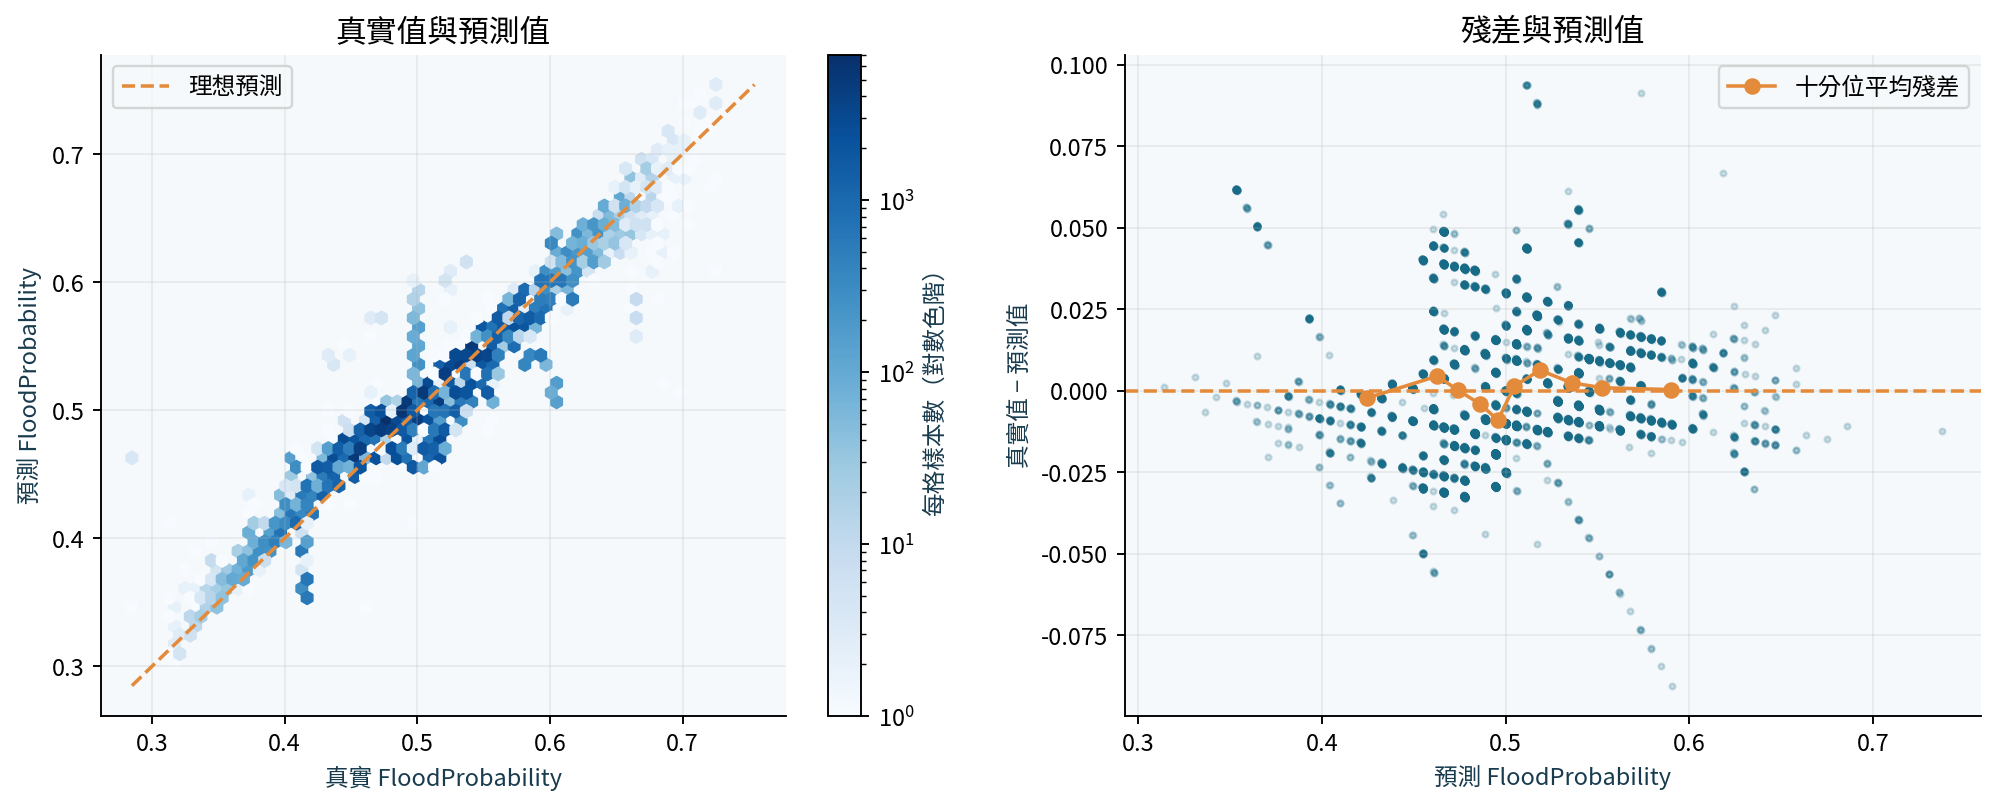

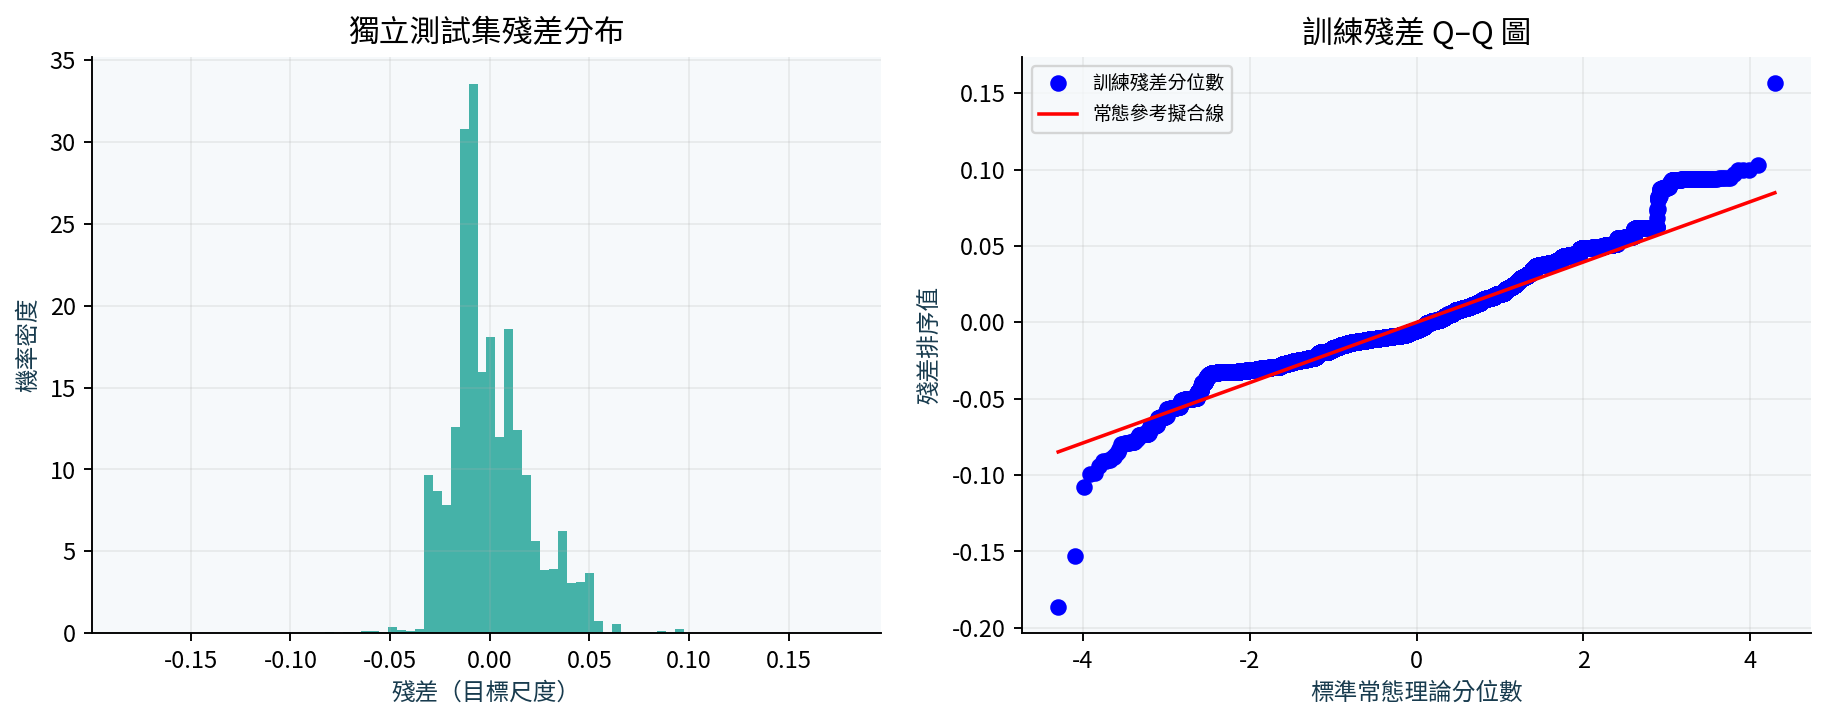

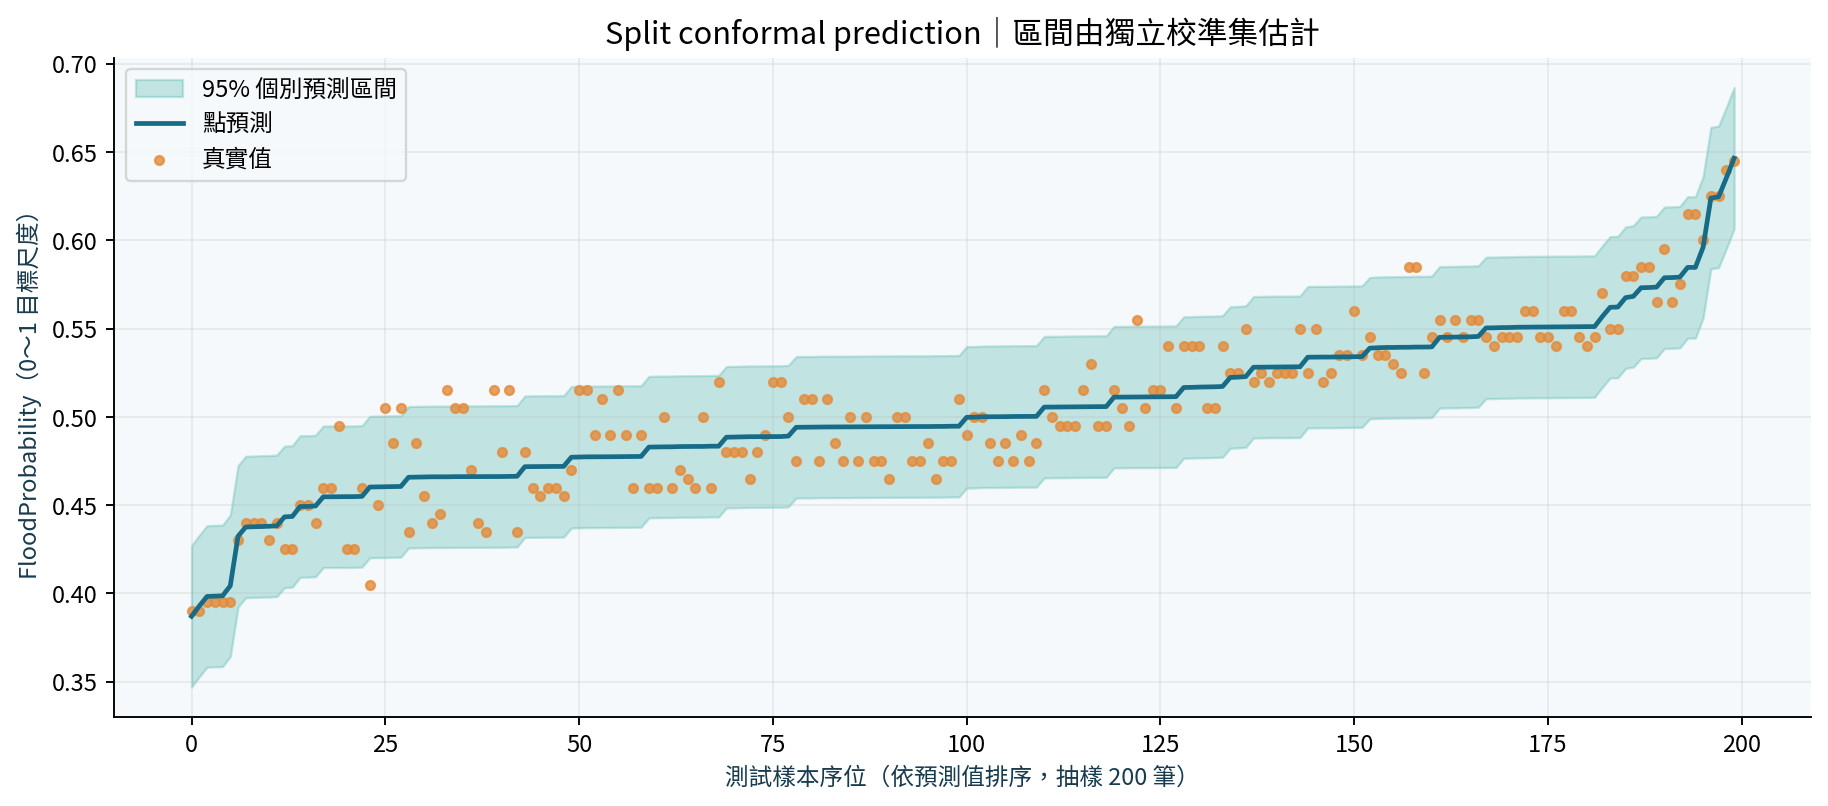

In [5]:
print(Path('outputs/tables/prediction_interval.json').read_text())
print(Path('outputs/tables/assumptions.json').read_text())
display(pd.read_csv('outputs/tables/conditional_diagnostics.csv'))
for name in ['06_predictions_residuals', '07_residual_distribution_qq', '10_prediction_intervals']:
    display(Image(filename=f'outputs/figures/{name}.png', width=850))

## Deployment
使用儲存的完整 Pipeline 與校準分位數預測。額外的 id 欄位會被忽略；缺少必要欄位或非法型別會回報錯誤。模型不裁切點預測或區間。Kaggle 提交模型另以全部標籤資料重訓，不能沿用此校準區間。

In [6]:
from src.prediction import predict_new_data
predictions = predict_new_data('data/processed/new_samples.csv')
display(predictions)
assert predictions.notna().all().all()
assert (predictions.lower_95 <= predictions.prediction).all()
assert (predictions.prediction <= predictions.upper_95).all()

,prediction,lower_95,upper_95
0,0.573548,0.533490,0.613606
1,0.455261,0.415203,0.495320
2,0.454875,0.414817,0.494933
3,0.466213,0.426155,0.506271
4,0.466140,0.426081,0.506198


## 研究文件與重現
公開分析本文見 web/downloads/report_analysis.pdf，研究來源見 research/sources.md。第二題與網站部署見 README.md、WEB_DEPLOYMENT.md。完整私人對話保留於本地作業包；未取得 Kaggle 官方排名。
此公開匯出只調整本段文件連結，程式儲存格與既有真實執行輸出均保留。重新執行 Notebook 會實際重訓，需先安裝完整研究依賴並下載字型。